# 02 · Feature Engineering and SageMaker Feature Store
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Turn 1.2 M unique events into one row per **actor × 5-minute window** with leakage-free behavioural features and the weak label, then publish the features to S3 and to the **SageMaker Feature Store**. |
| **Input (S3)** | `processed/events/part-*.parquet` (notebook 01) |
| **Output (S3)** | `features/feature_mart.parquet`, `features/csv/feature_mart.csv` · Feature group `cloudtrail-actor-window-features` (online + offline store) |
| **Next** | `03_train_tune_evaluate.ipynb` |

**Recommended Studio instance:** the windowed SQL needs more memory than `ml.t3.medium` (4 GB) comfortably offers. Use **`ml.m5.large`** (8 GB) for this notebook, then switch back.

## 1. Setup

In [1]:
%%capture pip_log
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
# Output is captured to keep the notebook clean; run print(pip_log.stdout) to see it.
# (Warnings about sagemaker-core / sagemaker-mlops conflicts refer to Studio's pre-installed
#  SDK v3 packages, which this project does not use.)
%pip install -q -r ../requirements.txt

In [2]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import time

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cloudtrail_mlops import aws, config, features
from cloudtrail_mlops.plots import BLUE, NORMAL, ORANGE, SUSPICIOUS, setup_style

setup_style()
ctx = aws.get_context()
state = aws.load_state(ctx)

# Re-use notebook 01's local copy, or fetch the processed events from S3 (e.g. on a teammate's Studio).
EVENTS_DIR = DATA_DIR / "events"
if not any(EVENTS_DIR.glob("part-*.parquet")):
    ctx.session.download_data(str(EVENTS_DIR), bucket=ctx.bucket, key_prefix=ctx.prefix("events"))
print(len(list(EVENTS_DIR.glob("part-*.parquet"))), "event Parquet files available")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
20 event Parquet files available


## 2. Why actor × 5-minute windows?
A single API call is rarely suspicious on its own (`ListBuckets` is routine for an admin and reconnaissance for an attacker). **What the actor did in a short burst, compared with their own past**, is far more informative. Each row of the feature mart therefore describes *one actor's activity in one 5-minute window*:

| feature group | examples | idea |
|---|---|---|
| activity in the window | `distinct_apis`, `write_count`, `error_count`, `auth_error_count`, `destructive_count` | how broad / risky / failing is the burst |
| novelty vs. the actor's past | `new_actor_api_count`, `new_actor_ip_count`, `globally_rare_api_count` | first-time APIs, IPs, user agents |
| strictly-prior history | `prior_errors_24h`, `prior_writes_24h`, `prior_new_apis_7d` | what the actor did in the previous 1 h / 24 h / 7 d |
| rates & calendar | `error_rate_current`, `write_rate_current`, `hour_sin/cos`, `dow_sin/cos` | scale-free versions + cyclical time |
| context (categorical) | `last_service`, `last_region`, `last_ua_family` | one-hot encoded in notebook 03 |

**Leakage controls built into the SQL (`src/cloudtrail_mlops/features.py`):**
* every history counter uses `ROWS/RANGE … PRECEDING` — the current and future events are never counted;
* the policy flags that **define** the label are kept in separate `*_current` audit columns and are **never** model inputs (checked by `dataset.leakage_violations` and a unit test);
* 9 "cumulative size" features (e.g. total prior events) grow with the log itself and drift by construction — they are computed for analysis but excluded from the model (`config.DRIFT_PRONE_FEATURES`).

**Target** `target_current_or_future_30m` = 1 if the window contains a policy-flagged event **or** the same actor triggers one within the next 30 minutes (early warning). The last 30 minutes of the log cannot be labelled and are left `NULL`.

## 3. Build the feature mart with DuckDB

In [3]:
start = time.time()
con = features.connect(temp_dir=DATA_DIR / "duckdb_tmp")
audit = features.build_feature_mart(con, (EVENTS_DIR / "part-*.parquet").as_posix())
print(f"Feature mart built in {time.time() - start:.0f} s")
audit.T.rename(columns={0: "value"})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Feature mart built in 26 s


,value
raw_events,1939207
unique_events,1225784
policy_flagged_events,361.0
actor_windows,75609
actors,185
first_window,2017-02-12 19:55:00+00:00
last_window,2020-10-07 21:00:00+00:00
positive_windows,393.0
unlabelled_tail_windows,7


In [4]:
mart = con.execute("SELECT * FROM feature_mart").fetchdf()
mart["window_start"] = pd.to_datetime(mart["window_start"], utc=True)

checks = features.validate_feature_mart(mart)
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "data-quality check failed - fix before training"
print(f"Feature mart: {mart.shape[0]:,} rows x {mart.shape[1]} columns | "
      f"model inputs: {len(config.NUMERIC_FEATURES)} numeric + {len(config.CATEGORICAL_FEATURES)} categorical")
mart[config.KEY_COLUMNS + config.FEATURE_COLUMNS[:8] + [config.TARGET_COLUMN]].head()

,passed
all_feature_columns_present,True
target_column_present,True
unique_actor_window_keys,True
target_is_binary,True
both_classes_present,True
no_policy_columns_in_features,True
no_infinite_numeric_values,True


Feature mart: 75,609 rows x 60 columns | model inputs: 35 numeric + 3 categorical


,actor_id,window_start,distinct_services,distinct_apis,distinct_regions,distinct_source_ips,distinct_ua_families,error_count,auth_error_count,write_count,target_current_or_future_30m
0,arn:aws:iam::811596193553:root,2017-02-12 19:55:00+00:00,2,6,1,1,1,2.0,0.0,0.0,1
1,arn:aws:iam::811596193553:root,2017-02-12 20:00:00+00:00,3,8,2,2,2,0.0,0.0,4.0,1
2,arn:aws:iam::811596193553:root,2017-02-12 20:05:00+00:00,4,30,2,2,2,1.0,0.0,1.0,0
3,arn:aws:iam::811596193553:root,2017-02-12 20:10:00+00:00,1,5,1,1,1,0.0,0.0,1.0,0
4,arn:aws:iam::811596193553:root,2017-02-12 20:15:00+00:00,3,5,2,1,2,0.0,0.0,0.0,0


## 4. Feature analysis

### 4.1 How rare is the positive class, and when does it occur?

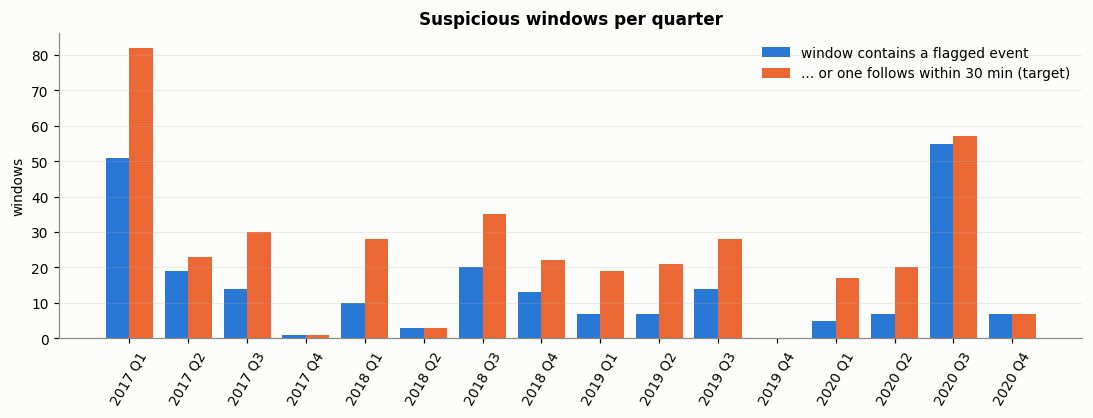

Prevalence of the target: 0.520% (393 of 75,602 windows)


In [5]:
labelled = mart[mart[config.TARGET_COLUMN].notna()]
quarterly = (labelled.set_index("window_start")
             .resample("QS")[["target_detection_current", config.TARGET_COLUMN]].sum())
quarterly.index = [f"{d.year} Q{(d.month - 1) // 3 + 1}" for d in quarterly.index]

fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(quarterly))
ax.bar(x - 0.2, quarterly["target_detection_current"], width=0.4, color=BLUE, label="window contains a flagged event")
ax.bar(x + 0.2, quarterly[config.TARGET_COLUMN], width=0.4, color=ORANGE, label="... or one follows within 30 min (target)")
ax.set_xticks(x, quarterly.index, rotation=60)
ax.set(title="Suspicious windows per quarter", ylabel="windows")
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()
print(f"Prevalence of the target: {labelled[config.TARGET_COLUMN].mean():.3%} "
      f"({int(labelled[config.TARGET_COLUMN].sum())} of {len(labelled):,} windows)")

**Observations.**
* **75,609 actor-windows from 185 actors; 393 are suspicious (0.52 %)** — 233 windows contain a flagged event, the rest are 30-minute early-warning windows.
* Positives come in **bursts**: 2017 Q1 (82 windows, the launch of the flAWS challenge) and 2020 Q3 (57, mostly public-exposure events) dominate, while **2019 Q4 has none at all**.
* This is why the split is chronological, why evaluation uses average precision and alert-budget recall (notebook 03), and why every result must be read with the small number of positives in mind.

### 4.2 Do the features separate suspicious from normal windows?

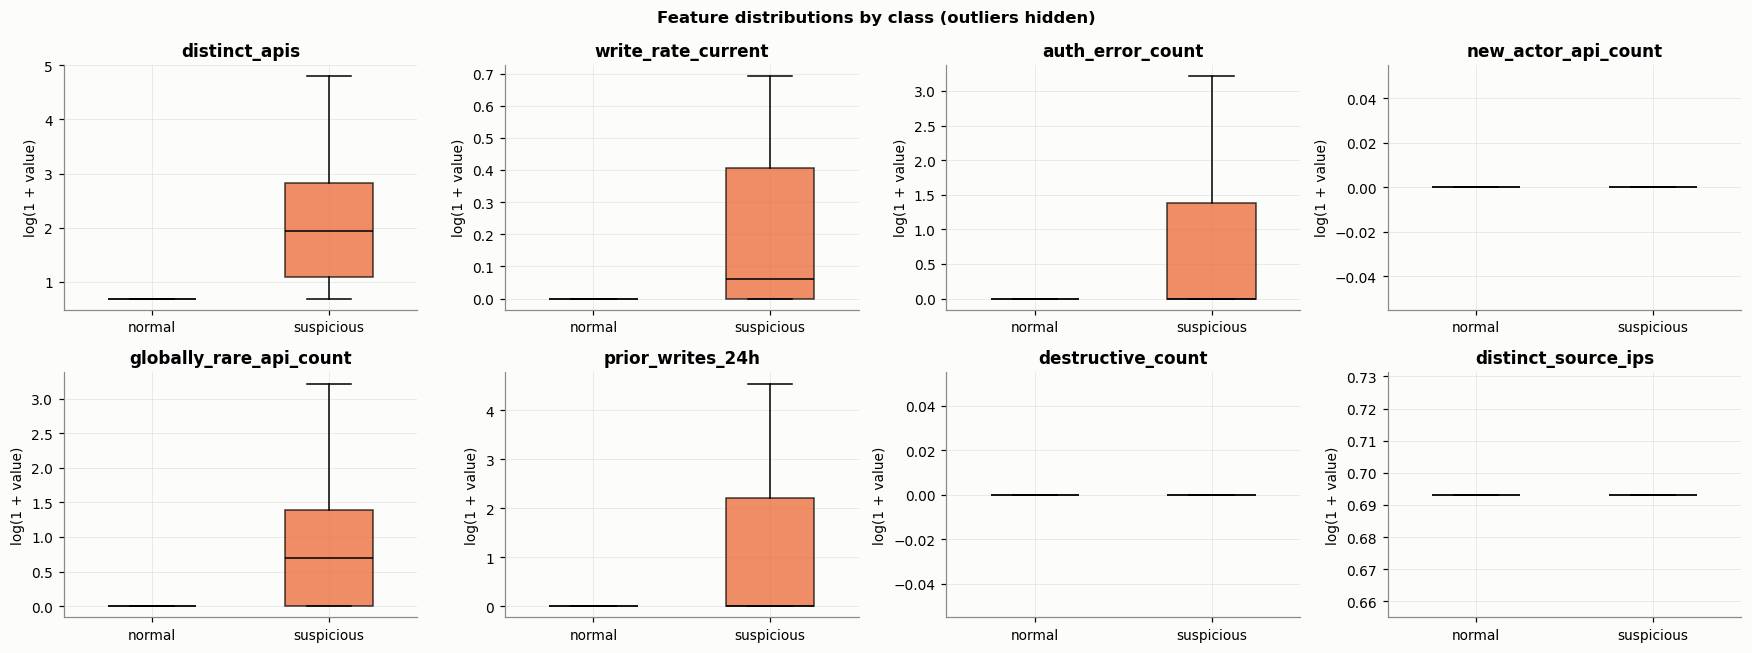

In [6]:
show = ["distinct_apis", "write_rate_current", "auth_error_count", "new_actor_api_count",
        "globally_rare_api_count", "prior_writes_24h", "destructive_count", "distinct_source_ips"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, column in zip(axes.ravel(), show):
    values = [np.log1p(labelled.loc[labelled[config.TARGET_COLUMN] == k, column].fillna(0).clip(lower=0)) for k in (0, 1)]
    parts = ax.boxplot(values, patch_artist=True, showfliers=False, widths=0.5, medianprops={"color": "black"})
    ax.set_xticks([1, 2], ["normal", "suspicious"])
    for patch, colour in zip(parts["boxes"], (NORMAL, SUSPICIOUS)):
        patch.set_facecolor(colour)
        patch.set_alpha(0.75)
    ax.set_title(column)
    ax.set_ylabel("log(1 + value)")
plt.suptitle("Feature distributions by class (outliers hidden)", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations.**
* Suspicious windows clearly differ on **`distinct_apis`** (median ≈ 6 vs 1), **`write_rate_current`**, **`auth_error_count`**, **`globally_rare_api_count`** and **`prior_writes_24h`**: an actor suddenly calling many different, rarely used, state-changing APIs — often with permission failures — after a period of writes.
* `new_actor_api_count`, `destructive_count` and `distinct_source_ips` have a median of 0 / 1 in **both** classes: they are non-zero only in a few windows. Medians cannot show such rare signals, but tree splits can still use them.
* No single feature separates the classes, which motivates a non-linear tree ensemble (XGBoost) rather than a single rule.

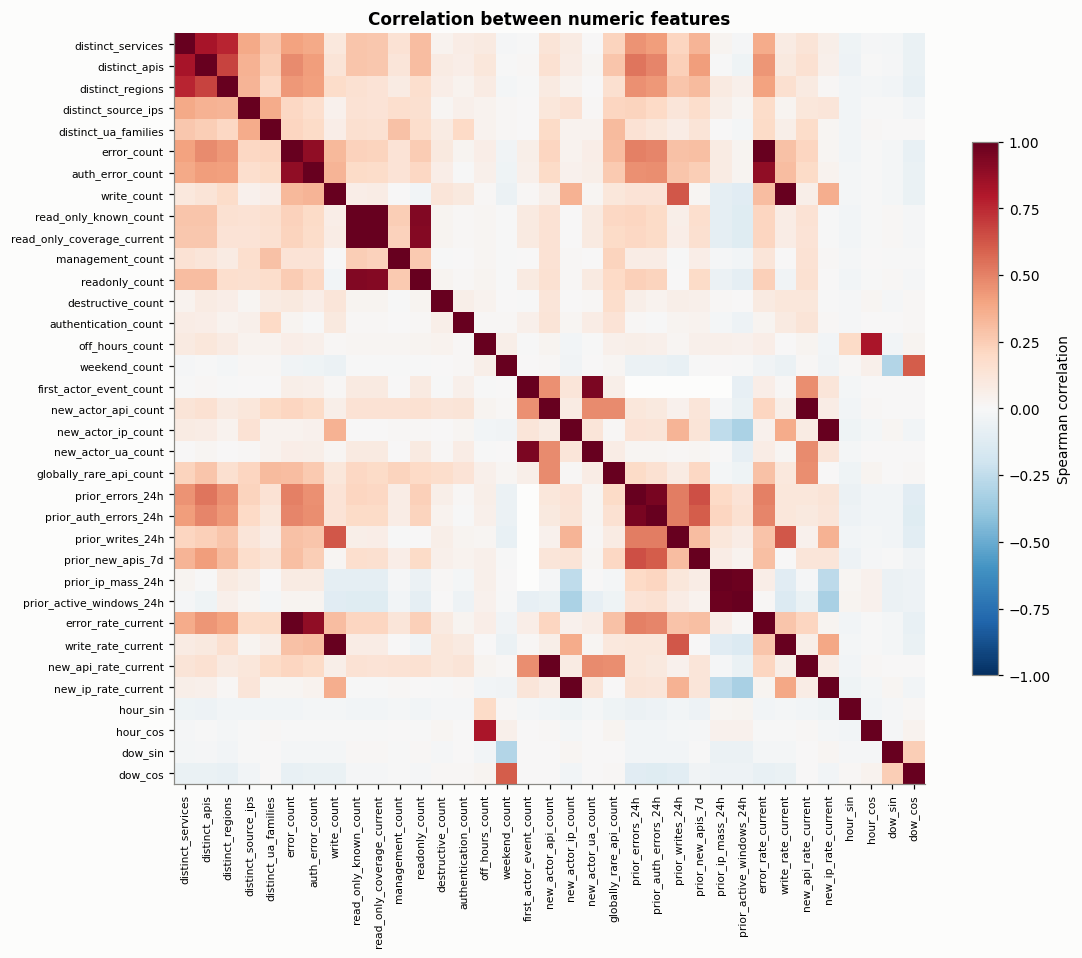

In [7]:
corr = labelled[config.NUMERIC_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Correlation between numeric features")
plt.show()

**Observation.** Several features are near-duplicates: counts and their rates (`write_count` / `write_rate_current`, `error_count` / `error_rate_current`), the read-only counters, and the 24-hour history pairs (`prior_errors_24h` / `prior_auth_errors_24h`, `prior_ip_mass_24h` / `prior_active_windows_24h`). Tree models are robust to correlated inputs, so they are kept; when explaining predictions we use per-prediction SHAP contributions (notebook 03) rather than reading single-feature importance in isolation.

## 5. Publish the feature mart to S3

In [8]:
FEATURE_DIR = DATA_DIR / "features"
(FEATURE_DIR / "csv").mkdir(parents=True, exist_ok=True)
features.export_feature_mart(con, FEATURE_DIR / "feature_mart.parquet", FEATURE_DIR / "csv" / "feature_mart.csv")
con.close()

mart_parquet_uri = ctx.session.upload_data(str(FEATURE_DIR / "feature_mart.parquet"), bucket=ctx.bucket, key_prefix=ctx.prefix("features"))
mart_csv_uri = ctx.session.upload_data(str(FEATURE_DIR / "csv" / "feature_mart.csv"), bucket=ctx.bucket, key_prefix=ctx.prefix("features") + "/csv")
aws.save_state(ctx, feature_mart_parquet=mart_parquet_uri, feature_mart_csv=mart_csv_uri)
print(mart_parquet_uri, mart_csv_uri, sep="\n")

s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/features/feature_mart.parquet
s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/features/csv/feature_mart.csv


## 6. SageMaker Feature Store
The engineered features are registered in a **feature group** with both stores enabled:
* **online store** — low-latency look-up of the latest features for an actor (what a real-time scoring service would read);
* **offline store** — append-only history in S3, queryable with Athena, used to build point-in-time-correct training sets.

`record_id = actor_id|window_start` identifies a row; `event_time` (epoch seconds of the window) lets the store keep the latest version per record. To keep ingestion quick and cheap we ingest the most recent `FS_ROWS` windows; the full mart remains in S3.

In [9]:
from botocore.exceptions import ClientError
from sagemaker.feature_store.feature_group import FeatureGroup

FEATURE_GROUP_NAME = "cloudtrail-actor-window-features"
FS_ROWS = 10_000   # most recent windows to ingest (set None to ingest everything; takes longer)

fs_df = mart.sort_values("window_start").tail(FS_ROWS).copy() if FS_ROWS else mart.copy()
fs_df["record_id"] = fs_df["actor_id"].astype(str) + "|" + fs_df["window_start"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
# seconds since 1970-01-01 (computed from the timedelta so it is correct for any datetime precision)
fs_df["event_time"] = (fs_df["window_start"] - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
fs_df["window_start"] = fs_df["window_start"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
fs_df["target"] = fs_df[config.TARGET_COLUMN].fillna(-1).astype("int64")   # -1 = not yet labelled
for column in config.NUMERIC_FEATURES:
    fs_df[column] = pd.to_numeric(fs_df[column], errors="coerce").fillna(0.0).astype("float64")
for column in config.CATEGORICAL_FEATURES + ["actor_id", "record_id", "window_start"]:
    fs_df[column] = fs_df[column].fillna("__missing__").astype(str).astype("string")
fs_df = fs_df[["record_id", "event_time", "actor_id", "window_start"] + config.FEATURE_COLUMNS + ["target"]].reset_index(drop=True)

assert fs_df["event_time"].between(1.4e9, 1.7e9).all(), "event_time must be epoch seconds (2017-2020)"

# Re-running this notebook rebuilds the feature group from scratch, so the store never mixes old and new records.
sm_client = ctx.session.sagemaker_client
try:
    sm_client.delete_feature_group(FeatureGroupName=FEATURE_GROUP_NAME)
    print("Deleting the previous version of the feature group ...")
    while True:
        sm_client.describe_feature_group(FeatureGroupName=FEATURE_GROUP_NAME)
        time.sleep(10)
except ClientError as error:
    if "ResourceNotFound" not in str(error):
        raise

feature_group = FeatureGroup(name=FEATURE_GROUP_NAME, sagemaker_session=ctx.session)
feature_group.load_feature_definitions(data_frame=fs_df)
feature_group.create(s3_uri=ctx.s3_uri("features", "feature-store"), record_identifier_name="record_id",
                     event_time_feature_name="event_time", role_arn=ctx.role, enable_online_store=True,
                     description="CloudTrail actor x 5-minute window behavioural features (AAI-540 Group 3)")

while feature_group.describe()["FeatureGroupStatus"] == "Creating":
    time.sleep(10)
print("Feature group status:", feature_group.describe()["FeatureGroupStatus"])

Deleting the previous version of the feature group ...
Feature group status: Created


In [10]:
start = time.time()
feature_group.ingest(data_frame=fs_df, max_workers=4, wait=True)
aws.save_state(ctx, feature_group=FEATURE_GROUP_NAME)
print(f"Ingested {len(fs_df):,} records in {time.time() - start:.0f} s")

description = feature_group.describe()
pd.Series({
    "Feature group": description["FeatureGroupName"],
    "Status": description["FeatureGroupStatus"],
    "Number of features": len(description["FeatureDefinitions"]),
    "Record identifier": description["RecordIdentifierFeatureName"],
    "Event time feature": description["EventTimeFeatureName"],
    "Online store": description["OnlineStoreConfig"]["EnableOnlineStore"],
    "Offline store (S3)": description["OfflineStoreConfig"]["S3StorageConfig"]["ResolvedOutputS3Uri"],
}, name="value").to_frame()

Ingested 10,000 records in 27 s


,value
Feature group,cloudtrail-actor-window-features
Status,Created
Number of features,43
Record identifier,record_id
Event time feature,event_time
Online store,True
Offline store (S3),s3://sagemaker-us-east-1-674905628044/cloudtra...


### 6.1 Online store: low-latency look-up of one actor-window

In [11]:
runtime = boto3.client("sagemaker-featurestore-runtime", region_name=ctx.region)
example_id = fs_df.loc[fs_df["target"] == 1, "record_id"].iloc[-1] if (fs_df["target"] == 1).any() else fs_df.record_id.iloc[-1]
record = runtime.get_record(FeatureGroupName=FEATURE_GROUP_NAME, RecordIdentifierValueAsString=example_id)["Record"]
print("Online look-up for", example_id)
pd.DataFrame(record).set_index("FeatureName").T

Online look-up for arn:aws:iam::811596193553:root|2020-10-07T15:50:00Z


FeatureName,record_id,event_time,actor_id,window_start,distinct_services,distinct_apis,distinct_regions,distinct_source_ips,distinct_ua_families,error_count,...,new_api_rate_current,new_ip_rate_current,hour_sin,hour_cos,dow_sin,dow_cos,last_service,last_region,last_ua_family,target
ValueAsString,arn:aws:iam::811596193553:root|2020-10-07T15:5...,1602085800.0,arn:aws:iam::811596193553:root,2020-10-07T15:50:00Z,3.0,16.0,1.0,1.0,2.0,2.0,...,0.0,0.0,-0.7071067811865471,-0.7071067811865479,0.43388373911755823,-0.900968867902419,iam.amazonaws.com,us-east-1,console,1


### 6.2 Offline store: query the feature history with Athena
The offline store is written asynchronously (usually 5–15 minutes after ingestion). If the query returns no rows yet, wait a few minutes and re-run this cell.

In [14]:
query = feature_group.athena_query()
query.run(query_string=f'''
    SELECT actor_id, window_start, distinct_apis, write_rate_current, auth_error_count, target
    FROM "{query.table_name}"
    WHERE target = 1
    ORDER BY window_start DESC
    LIMIT 10''', output_location=ctx.s3_uri("features", "athena-results") + "/")
query.wait()
query.as_dataframe()

,actor_id,window_start,distinct_apis,write_rate_current,auth_error_count,target
0,arn:aws:iam::811596193553:root,2020-10-07T15:50:00Z,16.0,0.030303,0.0,1
1,254.9.176.211,2020-10-07T07:25:00Z,16.0,0.500000,15.0,1
2,arn:aws:iam::811596193553:root,2020-10-06T21:10:00Z,34.0,0.115702,0.0,1
3,254.9.176.211,2020-10-06T14:05:00Z,16.0,0.500000,15.0,1
4,254.9.176.211,2020-10-05T07:10:00Z,16.0,0.500000,60.0,1
5,254.9.176.211,2020-10-01T12:05:00Z,16.0,0.500000,15.0,1
6,254.9.176.211,2020-10-01T02:00:00Z,16.0,0.500000,15.0,1
7,254.9.176.211,2020-09-30T15:10:00Z,16.0,0.500000,45.0,1
8,254.9.176.211,2020-09-29T10:05:00Z,16.0,0.500000,15.0,1
9,254.9.176.211,2020-09-29T02:00:00Z,16.0,0.500000,15.0,1


In [16]:
# Offline store = Parquet files that SageMaker writes to S3 (the same files Athena queries).
# Read directly with boto3 (works where Athena / Glue access is restricted). Only the newest
# files are read: the store holds many small files and a sample is enough to inspect it.
import io

s3 = boto3.client("s3")
prefix = ctx.prefix("features") + "/feature-store/"
objects = [obj
           for page in s3.get_paginator("list_objects_v2").paginate(Bucket=ctx.bucket, Prefix=prefix)
           for obj in page.get("Contents", [])
           if obj["Key"].endswith(".parquet") and FEATURE_GROUP_NAME in obj["Key"]]
print(f"Offline store: {len(objects)} Parquet files under s3://{ctx.bucket}/{prefix}")

newest = sorted(objects, key=lambda o: o["LastModified"], reverse=True)[:30]
if newest:
    offline = pd.concat([pd.read_parquet(io.BytesIO(s3.get_object(Bucket=ctx.bucket, Key=o["Key"])["Body"].read()))
                         for o in newest], ignore_index=True)
    print(f"Read {len(offline):,} records from the {len(newest)} newest files")
    display(offline[["actor_id", "window_start", "distinct_apis", "write_rate_current", "auth_error_count", "target"]]
            .sort_values(["target", "window_start"], ascending=False).head(10))
else:
    print("Offline store not written yet - SageMaker flushes it 5-15 minutes after ingestion. Re-run this cell later.")

Offline store: 10177 Parquet files under s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/features/feature-store/
Read 32 records from the 30 newest files


,actor_id,window_start,distinct_apis,write_rate_current,auth_error_count,target
0,arn:aws:iam::811596193553:user/backup,2020-08-30T11:35:00Z,1.0,1.0,69.0,0
31,arn:aws:sts::811596193553:assumed-role/Level6/...,2020-05-20T07:40:00Z,1.0,1.0,0.0,0
29,arn:aws:iam::811596193553:user/Level6,2020-05-20T07:25:00Z,7.0,0.0,2.0,0
30,arn:aws:iam::811596193553:user/Level6,2020-05-20T07:15:00Z,2.0,0.0,0.0,0
28,ec2.amazonaws.com,2020-05-19T15:45:00Z,1.0,0.0,0.0,0
27,arn:aws:sts::811596193553:assumed-role/Level6/...,2020-05-19T11:55:00Z,1.0,1.0,0.0,0
26,arn:aws:iam::811596193553:user/Level6,2020-05-18T16:05:00Z,2.0,0.0,0.0,0
25,ec2.amazonaws.com,2020-05-16T07:30:00Z,1.0,0.0,0.0,0
24,arn:aws:iam::811596193553:user/Level6,2020-05-14T22:00:00Z,2.0,0.0,4.0,0
23,ec2.amazonaws.com,2020-05-10T19:30:00Z,1.0,0.0,0.0,0


## 7. Summary
* **Feature mart**: one row per actor × 5-minute window, 35 numeric + 3 categorical leakage-free inputs, weak target with a 30-minute early-warning horizon; stored in S3 as Parquet (analytics) and CSV (pipeline input).
* **Feature Store**: online + offline feature group for serving-time look-ups and auditable training-data history.
* Data-quality checks (schema, unique keys, binary target, both classes, no leakage, finite values) run here **and** as the first step of the CI/CD pipeline (notebook 06).